# 06. Implementación del modelo Random Forest
En este cuaderno implemento un modelo Random Forest para predecir el resultado de los partidos de la Liga Panameña de Fútbol.
Mantengo el problema como una clasificación multiclase con tres categorías: victoria local (`L`), empate (`E`) y victoria visitante (`V`).
Utilizo los mismos conjuntos temporales empleados previamente para garantizar una comparación consistente con la Regresión Logística. Ajusto el modelo utilizando exclusivamente los partidos del conjunto de entrenamiento y empleo los encuentros de 2025 para seleccionar los hiperparámetros.
Mantengo los partidos correspondientes a 2026 y 2026/2027 completamente separados hasta finalizar la selección del modelo.
Debido a que Random Forest puede representar relaciones no lineales e interacciones entre características, evalúo si este algoritmo logra capturar patrones que la Regresión Logística no pudo representar adecuadamente.

# Celda 2 Librerías

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


# Celda 3 Rutas y carga
## 1. Carga de los conjuntos temporales
Cargo los conjuntos de entrenamiento, validación y prueba previamente construidos.
Mantengo la misma partición utilizada con la Regresión Logística para que la comparación posterior entre ambos algoritmos se realice bajo exactamente las mismas condiciones.

In [2]:
ROOT = Path("..").resolve()

PROCESSED_DIR = (
    ROOT
    / "data"
    / "processed"
)

FIGURES_DIR = (
    ROOT
    / "figures"
)

MODELS_DIR = (
    ROOT
    / "models"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_PATH = (
    PROCESSED_DIR
    / "lpf_train.csv"
)

VALIDACION_PATH = (
    PROCESSED_DIR
    / "lpf_validacion.csv"
)

TEST_PATH = (
    PROCESSED_DIR
    / "lpf_test.csv"
)

df_train = pd.read_csv(
    TRAIN_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_validacion = pd.read_csv(
    VALIDACION_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_test = pd.read_csv(
    TEST_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

print(
    "Entrenamiento:",
    df_train.shape
)

print(
    "Validación:",
    df_validacion.shape
)

print(
    "Prueba:",
    df_test.shape
)

Entrenamiento: (1869, 55)
Validación: (206, 55)
Prueba: (151, 55)


# Celda 4  Comprobación temporal
### 1.1. Verificación temporal
Antes de entrenar Random Forest verifico que los partidos del conjunto de entrenamiento sean anteriores a validación y que el conjunto de prueba permanezca cronológicamente posterior.
Esta comprobación me permite mantener las mismas condiciones metodológicas utilizadas en el modelo anterior.

In [3]:
print(
    "Train:",
    df_train["fecha_partido"].min(),
    "→",
    df_train["fecha_partido"].max()
)

print(
    "Validación:",
    df_validacion["fecha_partido"].min(),
    "→",
    df_validacion["fecha_partido"].max()
)

print(
    "Prueba:",
    df_test["fecha_partido"].min(),
    "→",
    df_test["fecha_partido"].max()
)

assert (
    df_train["fecha_partido"].max()
    <
    df_validacion["fecha_partido"].min()
)

assert (
    df_validacion["fecha_partido"].max()
    <
    df_test["fecha_partido"].min()
)

print(
    "\nSeparación temporal correcta."
)

Train: 2014-07-18 00:00:00 → 2024-11-30 00:00:00
Validación: 2025-01-17 00:00:00 → 2025-11-29 00:00:00
Prueba: 2026-01-16 00:00:00 → 2026-09-14 00:00:00

Separación temporal correcta.


# Celda 5  Variables de entrada
## 2. Definición de las variables
Utilizo las mismas características empleadas en la Regresión Logística para garantizar que las diferencias de rendimiento se deban principalmente al algoritmo y no a cambios en las variables de entrada.
Mantengo 44 variables numéricas y 4 variables categóricas. Los goles finales y el resultado del partido permanecen excluidos de las características predictivas.

In [4]:
columnas_no_predictoras = [
    "registro_id",
    "fecha_partido",
    "temporada",
    "home_team_goal_count",
    "away_team_goal_count",
    "total_goal_count",
    "resultado"
]

columnas_categoricas = [
    "home_team_name",
    "away_team_name",
    "mes_partido",
    "dia_semana"
]

columnas_numericas = [
    columna
    for columna in df_train.columns
    if (
        columna
        not in columnas_no_predictoras
        and columna
        not in columnas_categoricas
    )
]

columnas_X = (
    columnas_numericas
    + columnas_categoricas
)

print(
    "Variables numéricas:",
    len(columnas_numericas)
)

print(
    "Variables categóricas:",
    len(columnas_categoricas)
)

print(
    "Total de predictores:",
    len(columnas_X)
)

Variables numéricas: 44
Variables categóricas: 4
Total de predictores: 48


# Celda 6. Extracción de variables predictoras ($X$) y variable objetivo ($y$)
# 2.2. Construcción de los conjuntos de entrada y salida
Una vez que separé las particiones temporales y definí las columnas a utilizar, extraigo las matrices de características de entrada (X_train, X_validacion, X_test) y los vectores con la variable objetivo (y_train, y_validacion, y_test).En esta celda utilizo .copy() para garantizar la independencia en memoria de cada subconjunto. Al separar las características del resultado final ("resultado"), dejo las estructuras listas para las etapas de entrenamiento y evaluación, comprobando además las dimensiones resultantes de cada conjunto.

In [5]:
# extraer matrices de entrada y vectores objetivo para entrenamiento
X_train = (
    df_train[
        columnas_X
    ].copy()
)

y_train = (
    df_train[
        "resultado"
    ].copy()
)

# extraer matrices de entrada y vectores objetivo para validación
X_validacion = (
    df_validacion[
        columnas_X
    ].copy()
)

y_validacion = (
    df_validacion[
        "resultado"
    ].copy()
)

# extraer matrices de entrada y vectores objetivo para prueba
X_test = (
    df_test[
        columnas_X
    ].copy()
)

y_test = (
    df_test[
        "resultado"
    ].copy()
)

# comprobar las dimensiones resultantes de cada subconjunto
print(
    "X_train:",
    X_train.shape,
    "| y_train:",
    y_train.shape
)

print(
    "X_validación:",
    X_validacion.shape,
    "| y_validación:",
    y_validacion.shape
)

print(
    "X_test:",
    X_test.shape,
    "| y_test:",
    y_test.shape
)

X_train: (1869, 48) | y_train: (1869,)
X_validación: (206, 48) | y_validación: (206,)
X_test: (151, 48) | y_test: (151,)


# Celda 7 Baseline
### 2.1. Línea base de referencia
Mantengo como referencia la estrategia de predecir siempre la clase mayoritaria determinada exclusivamente mediante el conjunto de entrenamiento.
Utilizo esta misma línea base para facilitar posteriormente la comparación entre Regresión Logística, Random Forest y los demás modelos.

In [6]:
clase_baseline = (
    y_train
    .value_counts()
    .idxmax()
)

baseline_validacion = (
    y_validacion
    .eq(clase_baseline)
    .mean()
)

print(
    "Clase baseline:",
    clase_baseline
)

print(
    "Accuracy baseline validación:",
    f"{baseline_validacion * 100:.2f}%"
)

Clase baseline: L
Accuracy baseline validación: 36.41%


# Celda 8 Preprocesamiento para Random Forest
## 3. Preprocesamiento para Random Forest
Antes del entrenamiento sustituyo los valores faltantes de las variables numéricas mediante la mediana calculada exclusivamente sobre el conjunto de entrenamiento.
Para las variables categóricas utilizo imputación mediante la categoría más frecuente y posteriormente aplico codificación One-Hot.
A diferencia de la Regresión Logística, no aplico escalado a las variables numéricas, debido a que Random Forest construye árboles mediante comparaciones y umbrales, por lo que no necesita que las características se encuentren dentro de una misma escala.
Mantengo `handle_unknown="ignore"` para permitir el procesamiento de equipos no observados durante el entrenamiento.

In [8]:
pipeline_numerico_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)

pipeline_categorico_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocesador_rf = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico_rf,
            columnas_numericas
        ),
        (
            "categoricas",
            pipeline_categorico_rf,
            columnas_categoricas
        )
    ]
)

print(
    "Preprocesador Random Forest construido."
)

Preprocesador Random Forest construido.


# Celda 9  Random Forest base
## 4. Entrenamiento del Random Forest base
Construyo inicialmente un Random Forest con 300 árboles y parámetros generales del algoritmo.
Utilizo esta configuración como referencia antes de realizar el ajuste de hiperparámetros. Mantengo un `random_state` fijo para facilitar la reproducibilidad de los resultados y utilizo todos los núcleos disponibles mediante `n_jobs=-1`.

In [9]:
modelo_rf_base = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_rf
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                max_features="sqrt",
                class_weight=None,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

modelo_rf_base.fit(
    X_train,
    y_train
)

print(
    "Random Forest base entrenado correctamente."
)

Random Forest base entrenado correctamente.


# Celda 10. Predicciones del modelo Random Forest base en validación
# Inferencia sobre el conjunto de validación
Una vez entrenado el modelo inicial de Random Forest (modelo_rf_base), genero las predicciones directas de clase y la matriz de probabilidades asociadas sobre el subconjunto de validación (X_validacion).
En esta celda utilizo los métodos .predict() y .predict_proba() del pipeline. A través de las salidas impresas, verifico que la cantidad de predicciones coincida con las observaciones de validación, que las dimensiones de las probabilidades corresponden a las 3 clases objetivo y confirmo el orden exacto de las categorías en el estimador (classes_).

In [10]:
# generar predicciones de clase para el conjunto de validación
pred_validacion_rf_base = (
    modelo_rf_base.predict(
        X_validacion
    )
)

# calcular probabilidades de pertenencia a cada clase (L, E, V)
proba_validacion_rf_base = (
    modelo_rf_base.predict_proba(
        X_validacion
    )
)

# verificar las dimensiones y el orden de clases
print(
    "Predicciones:",
    len(pred_validacion_rf_base)
)

print(
    "Probabilidades:",
    proba_validacion_rf_base.shape
)

print(
    "Clases:",
    modelo_rf_base.named_steps[
        "modelo"
    ].classes_
)

Predicciones: 206
Probabilidades: (206, 3)
Clases: ['E' 'L' 'V']


# Celda 11  Métricas del modelo base
### 4.1. Evaluación inicial sobre validación
Evalúo el Random Forest inicial utilizando las mismas métricas aplicadas a la Regresión Logística.
Mantengo el F1-Score Macro como una de las principales medidas de desempeño debido a que permite evaluar de forma equilibrada las tres categorías de resultado.

In [11]:
metricas_rf_base = {
    "accuracy": accuracy_score(
        y_validacion,
        pred_validacion_rf_base
    ),

    "precision_macro": precision_score(
        y_validacion,
        pred_validacion_rf_base,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_validacion,
        pred_validacion_rf_base,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_validacion,
        pred_validacion_rf_base,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_validacion,
        proba_validacion_rf_base,
        labels=modelo_rf_base.named_steps[
            "modelo"
        ].classes_
    )
}

for metrica, valor in metricas_rf_base.items():
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.3738
precision_macro: 0.3460
recall_macro: 0.3610
f1_macro: 0.3322
log_loss: 1.0983


# Celda 12. Comparación de Random Forest contra la línea base (Baseline)
# Evaluación de desempeño frente al modelo trivial
Comparo la exactitud (Accuracy) obtenida por el modelo de Random Forest inicial (metricas_rf_base['accuracy']) frente al rendimiento de la línea base en el conjunto de validación (baseline_validacion).
En esta celda calculo la diferencia en puntos porcentuales entre la exactitud del modelo basado en árboles y la regla trivial de predecir únicamente la clase mayoritaria. Esto me permite medir de forma directa el beneficio de incorporar Random Forest antes de comenzar el proceso de ajuste de hiperparámetros.

In [12]:
# mostrar la exactitud de Random Forest vs. la línea base en validación
print(
    "Accuracy Random Forest:",
    f"{metricas_rf_base['accuracy'] * 100:.2f}%"
)

print(
    "Accuracy baseline:",
    f"{baseline_validacion * 100:.2f}%"
)

print(
    "Diferencia:",
    f"{(metricas_rf_base['accuracy'] - baseline_validacion) * 100:.2f}",
    "puntos porcentuales"
)

Accuracy Random Forest: 37.38%
Accuracy baseline: 36.41%
Diferencia: 0.97 puntos porcentuales


# Celda 13 Reporte por clase
### 4.2. Rendimiento por clase
Analizo el comportamiento individual de Random Forest sobre victorias locales, empates y victorias visitantes.
Esta revisión me permite comprobar si el uso de relaciones no lineales mejora especialmente la clasificación de empates, que representó la principal limitación de la Regresión Logística.

In [13]:
reporte_rf_base = (
    classification_report(
        y_validacion,
        pred_validacion_rf_base,
        labels=[
            "L",
            "E",
            "V"
        ],
        output_dict=True,
        zero_division=0
    )
)

df_reporte_rf_base = (
    pd.DataFrame(
        reporte_rf_base
    )
    .T
)

display(
    df_reporte_rf_base.round(4)
)

,precision,recall,f1-score,support
L,0.4000,0.6667,0.5000,75.0000
E,0.2581,0.1194,0.1633,67.0000
V,0.3800,0.2969,0.3333,64.0000
accuracy,0.3738,0.3738,0.3738,0.3738
macro avg,0.3460,0.3610,0.3322,206.0000
weighted avg,0.3476,0.3738,0.3387,206.0000


# Celda 14 Matriz de confusión base

In [14]:
matriz_rf_base = confusion_matrix(
    y_validacion,
    pred_validacion_rf_base,
    labels=["L", "E", "V"]
)

df_matriz_rf_base = pd.DataFrame(
    matriz_rf_base,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(df_matriz_rf_base)

,Pred L,Pred E,Pred V
Real L,50,10,15
Real E,43,8,16
Real V,32,13,19


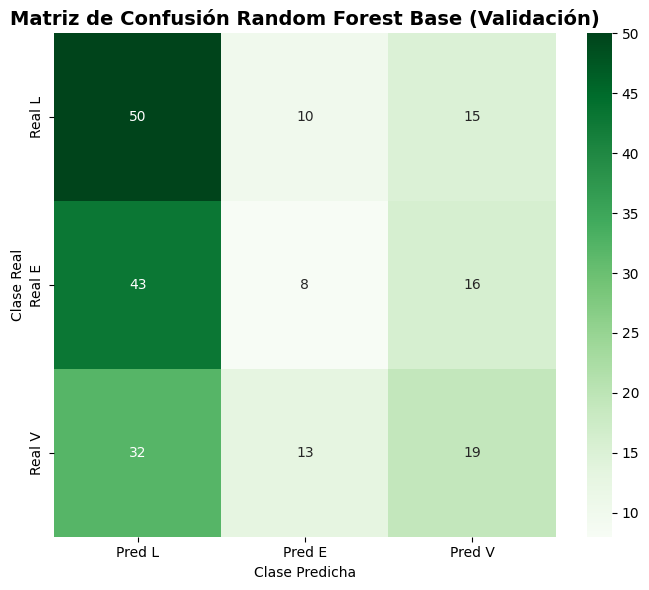

In [15]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_rf_base,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión Random Forest Base (Validación)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "random_forest_base_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 15. Comparación de frecuencias reales y predichas (Random Forest)
# Auditoría de la distribución de clases predichas en validación
Para examinar la tendencia de predicción del modelo Random Forest base y verificar si presenta algún sesgo hacia la clase mayoritaria o hacia los empates en el conjunto de validación, comparo el conteo total de observaciones reales contra las frecuencias asignadas por el modelo.
En esta celda estructuro el DataFrame comparacion_clases_rf combinando las salidas de .value_counts() sobre y_validacion y pred_validacion_rf_base. Reordeno explícitamente el índice con .reindex(["L", "E", "V"], fill_value=0) para facilitar la lectura inmediata de las tres categorías en la tabla.

In [16]:
# estructurar la tabla comparativa de frecuencias reales vs. predichas para Random Forest
comparacion_clases_rf = pd.DataFrame({
    "Real": (
        y_validacion
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    ),

    "Predicho": (
        pd.Series(
            pred_validacion_rf_base
        )
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    )
})

# desplegar la tabla de distribución en validación
display(
    comparacion_clases_rf
)

,Real,Predicho
L,75,125
E,67,31
V,64,50


# Celda 16 Ajuste controlado de hiperparámetrosç
## 5. Ajuste de hiperparámetros
Comparo diferentes configuraciones de Random Forest modificando el número de árboles, la profundidad máxima, el número mínimo de observaciones requeridas en las hojas y la ponderación de las clases.
Utilizo exclusivamente el conjunto de validación para seleccionar la configuración.
Mantengo el F1-Score Macro como criterio principal debido a que busco un comportamiento equilibrado entre las tres categorías. Utilizo Accuracy y Log Loss como métricas complementarias.
El conjunto de prueba permanece completamente separado durante esta etapa.

In [17]:
valores_n_estimators = [
    300,
    500
]

valores_max_depth = [
    6,
    10,
    15,
    None
]

valores_min_samples_leaf = [
    1,
    3,
    5
]

valores_class_weight = [
    None,
    "balanced"
]

resultados_rf = []

In [18]:
for n_estimators in valores_n_estimators:

    for max_depth in valores_max_depth:

        for min_samples_leaf in valores_min_samples_leaf:

            for class_weight in valores_class_weight:

                pipeline_actual = Pipeline(
                    steps=[
                        (
                            "preprocesamiento",
                            preprocesador_rf
                        ),
                        (
                            "modelo",
                            RandomForestClassifier(
                                n_estimators=n_estimators,
                                max_depth=max_depth,
                                min_samples_split=2,
                                min_samples_leaf=min_samples_leaf,
                                max_features="sqrt",
                                class_weight=class_weight,
                                random_state=42,
                                n_jobs=-1
                            )
                        )
                    ]
                )

                pipeline_actual.fit(
                    X_train,
                    y_train
                )

                pred_actual = (
                    pipeline_actual.predict(
                        X_validacion
                    )
                )

                proba_actual = (
                    pipeline_actual.predict_proba(
                        X_validacion
                    )
                )

                resultados_rf.append({
                    "n_estimators": n_estimators,

                    "max_depth": (
                        "None"
                        if max_depth is None
                        else max_depth
                    ),

                    "min_samples_leaf":
                        min_samples_leaf,

                    "class_weight": (
                        "None"
                        if class_weight is None
                        else class_weight
                    ),

                    "accuracy": accuracy_score(
                        y_validacion,
                        pred_actual
                    ),

                    "precision_macro":
                        precision_score(
                            y_validacion,
                            pred_actual,
                            average="macro",
                            zero_division=0
                        ),

                    "recall_macro":
                        recall_score(
                            y_validacion,
                            pred_actual,
                            average="macro",
                            zero_division=0
                        ),

                    "f1_macro":
                        f1_score(
                            y_validacion,
                            pred_actual,
                            average="macro",
                            zero_division=0
                        ),

                    "log_loss":
                        log_loss(
                            y_validacion,
                            proba_actual,
                            labels=pipeline_actual.named_steps[
                                "modelo"
                            ].classes_
                        )
                })

# Celda 17. Ordenamiento y selección de las mejores configuraciones 
# 4.2. Evaluación y jerarquización de combinaciones de hiperparámetros
Para determinar la mejor combinación de hiperparámetros del modelo Random Forest sobre el conjunto de validación, consolido todas las iteraciones en el DataFrame df_resultados_rf.En esta celda ordeno los resultados aplicando un criterio jerárquico prioritario: maximizo en primer lugar el ("f1_macro"), seguido de la exactitud ("accuracy"), y utilizo la pérdida logarítmica ("log_loss") como desempate en orden ascendente. Finalmente, despliego las 20 mejores configuraciones redondeadas a cuatro decimales para seleccionar la combinación óptima.

In [19]:
# ordenar las configuraciones evaluadas según las métricas clave
df_resultados_rf = (
    pd.DataFrame(
        resultados_rf
    )
    .sort_values(
        [
            "f1_macro",
            "accuracy",
            "log_loss"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

# mostrar las 20 mejores combinaciones de hiperparámetros
display(
    df_resultados_rf.head(20).round(4)
)

,n_estimators,max_depth,min_samples_leaf,class_weight,accuracy,precision_macro,recall_macro,f1_macro,log_loss
0,500,6,5,balanced,0.4029,0.3917,0.3990,0.3901,1.0867
1,500,10,1,None,0.4369,0.4312,0.4231,0.3894,1.0894
2,300,15,5,balanced,0.3981,0.3930,0.3925,0.3822,1.0847
3,300,6,5,balanced,0.3981,0.3891,0.3925,0.3813,1.0874
4,500,6,3,balanced,0.3932,0.3850,0.3886,0.3801,1.0840
5,500,15,5,None,0.4320,0.4169,0.4174,0.3792,1.0929
6,500,10,1,balanced,0.3932,0.3836,0.3881,0.3778,1.0813
7,500,None,3,balanced,0.3981,0.3869,0.3894,0.3765,1.0901
8,500,6,1,balanced,0.3883,0.3767,0.3836,0.3743,1.0850
9,500,10,5,balanced,0.3932,0.3779,0.3878,0.3740,1.0862


# Celda 18. Extracción e inspección de la mejor combinación de hiperparámetros
# 4.3. Selección de la arquitectura óptima de Random Forest
Una vez ordenado el ranking de búsquedas, extraigo la primera fila de la tabla (df_resultados_rf.iloc[0]), la cual contiene la combinación de hiperparámetros con mejor rendimiento multiclase en el conjunto de validación.
En esta celda imprimo los valores óptimos seleccionados para el modelo —número de árboles (n_estimators), profundidad máxima (max_depth), muestras mínimas en hojas (min_samples_leaf) y balanceo de clases (class_weight)— junto con sus correspondientes métricas de evaluación redondeadas a cuatro decimales.

In [20]:
# extraer la combinación óptima que ocupa la primera posición del ranking
mejor_rf = (
    df_resultados_rf.iloc[0]
)

# desplegar los hiperparámetros y las métricas asociadas
print(
    "Mejor configuración Random Forest:"
)

print(
    "n_estimators:",
    mejor_rf[
        "n_estimators"
    ]
)

print(
    "max_depth:",
    mejor_rf[
        "max_depth"
    ]
)

print(
    "min_samples_leaf:",
    mejor_rf[
        "min_samples_leaf"
    ]
)

print(
    "class_weight:",
    mejor_rf[
        "class_weight"
    ]
)

print(
    "\nAccuracy:",
    round(
        mejor_rf[
            "accuracy"
        ],
        4
    )
)

print(
    "Precision Macro:",
    round(
        mejor_rf[
            "precision_macro"
        ],
        4
    )
)

print(
    "Recall Macro:",
    round(
        mejor_rf[
            "recall_macro"
        ],
        4
    )
)

print(
    "F1 Macro:",
    round(
        mejor_rf[
            "f1_macro"
        ],
        4
    )
)

print(
    "Log Loss:",
    round(
        mejor_rf[
            "log_loss"
        ],
        4
    )
)

Mejor configuración Random Forest:
n_estimators: 500
max_depth: 6
min_samples_leaf: 5
class_weight: balanced

Accuracy: 0.4029
Precision Macro: 0.3917
Recall Macro: 0.399
F1 Macro: 0.3901
Log Loss: 1.0867


# Celda 19. Conversión y congelamiento de hiperparámetros óptimos
# 4.4. Preparación de parámetros para el modelo final
Para evitar errores de tipo de dato al instanciar el modelo definitivo, convierto las variables de la mejor configuración extraída (mejor_rf) a sus tipos nativos de Python (int o None).
En esta celda parseo la profundidad máxima (MAX_DEPTH_FINAL), la ponderación de clases (CLASS_WEIGHT_FINAL), la cantidad de árboles (N_ESTIMATORS_FINAL) y las muestras mínimas por hoja (MIN_SAMPLES_LEAF_FINAL). Al imprimir estos valores confirmados, dejo congelada la configuración que utilizaré para ajustar el modelo sobre la partición completa de entrenamiento.

In [21]:
# parsear y convertir los hiperparámetros óptimos a sus tipos nativos
MAX_DEPTH_FINAL = (
    None
    if mejor_rf["max_depth"] == "None"
    else int(
        mejor_rf["max_depth"]
    )
)

CLASS_WEIGHT_FINAL = (
    None
    if mejor_rf[
        "class_weight"
    ] == "None"
    else mejor_rf[
        "class_weight"
    ]
)

N_ESTIMATORS_FINAL = int(
    mejor_rf[
        "n_estimators"
    ]
)

MIN_SAMPLES_LEAF_FINAL = int(
    mejor_rf[
        "min_samples_leaf"
    ]
)

# confirmar en pantalla los parámetros finales congelados
print(
    "Configuración congelada:"
)

print(
    "n_estimators:",
    N_ESTIMATORS_FINAL
)

print(
    "max_depth:",
    MAX_DEPTH_FINAL
)

print(
    "min_samples_leaf:",
    MIN_SAMPLES_LEAF_FINAL
)

print(
    "class_weight:",
    CLASS_WEIGHT_FINAL
)

Configuración congelada:
n_estimators: 500
max_depth: 6
min_samples_leaf: 5
class_weight: balanced


In [22]:
modelo_rf_seleccionado = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_rf
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=
                    N_ESTIMATORS_FINAL,

                max_depth=
                    MAX_DEPTH_FINAL,

                min_samples_split=2,

                min_samples_leaf=
                    MIN_SAMPLES_LEAF_FINAL,

                max_features="sqrt",

                class_weight=
                    CLASS_WEIGHT_FINAL,

                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

modelo_rf_seleccionado.fit(
    X_train,
    y_train
)

pred_rf_validacion_final = (
    modelo_rf_seleccionado.predict(
        X_validacion
    )
)

proba_rf_validacion_final = (
    modelo_rf_seleccionado.predict_proba(
        X_validacion
    )
)

print(
    "Random Forest seleccionado entrenado."
)

Random Forest seleccionado entrenado.


# Celda 20  Reporte del Random Forest seleccionado

In [23]:
reporte_rf_final = (
    classification_report(
        y_validacion,
        pred_rf_validacion_final,
        labels=["L", "E", "V"],
        output_dict=True,
        zero_division=0
    )
)

df_reporte_rf_final = (
    pd.DataFrame(
        reporte_rf_final
    )
    .T
)

display(
    df_reporte_rf_final.round(4)
)

,precision,recall,f1-score,support
L,0.4333,0.5200,0.4727,75.0000
E,0.3333,0.2239,0.2679,67.0000
V,0.4085,0.4531,0.4296,64.0000
accuracy,0.4029,0.4029,0.4029,0.4029
macro avg,0.3917,0.3990,0.3901,206.0000
weighted avg,0.3931,0.4029,0.3927,206.0000


# Celda 21 Matriz optimizada

In [24]:
matriz_rf_final = confusion_matrix(
    y_validacion,
    pred_rf_validacion_final,
    labels=["L", "E", "V"]
)

df_matriz_rf_final = pd.DataFrame(
    matriz_rf_final,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_rf_final
)

,Pred L,Pred E,Pred V
Real L,39,15,21
Real E,31,15,21
Real V,20,15,29


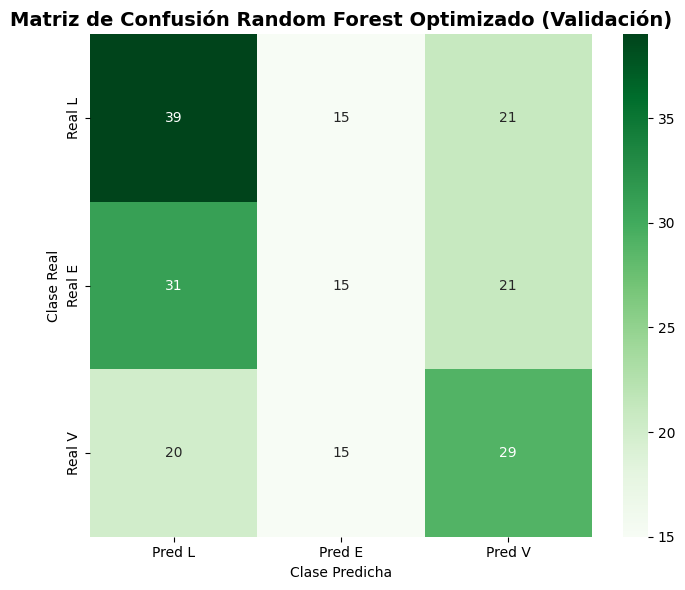

In [25]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_rf_final,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión Random Forest Optimizado (Validación)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "random_forest_optimizado_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 22 Comparación con Regresión Logística
## 6. Comparación preliminar con la Regresión Logística
Comparo el mejor Random Forest obtenido durante validación con la Regresión Logística previamente seleccionada.
Utilizo exactamente el mismo conjunto de validación, por lo que las diferencias observadas pueden atribuirse directamente al comportamiento de los algoritmos bajo las mismas condiciones temporales.

In [26]:
metricas_rf_validacion = {
    "accuracy": accuracy_score(
        y_validacion,
        pred_rf_validacion_final
    ),

    "precision_macro": precision_score(
        y_validacion,
        pred_rf_validacion_final,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_validacion,
        pred_rf_validacion_final,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_validacion,
        pred_rf_validacion_final,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_validacion,
        proba_rf_validacion_final,
        labels=modelo_rf_seleccionado.named_steps[
            "modelo"
        ].classes_
    )
}

comparacion_validacion = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Logística",
        "Random Forest"
    ],

    "Accuracy": [
        baseline_validacion,
        0.3981,
        metricas_rf_validacion[
            "accuracy"
        ]
    ],

    "F1 Macro": [
        np.nan,
        0.3833,
        metricas_rf_validacion[
            "f1_macro"
        ]
    ],

    "Log Loss": [
        np.nan,
        1.0897,
        metricas_rf_validacion[
            "log_loss"
        ]
    ]
})

display(
    comparacion_validacion.round(4)
)

,Modelo,Accuracy,F1 Macro,Log Loss
0,Baseline,0.3641,NaN,NaN
1,Regresión Logística,0.3981,0.3833,1.0897
2,Random Forest,0.4029,0.3901,1.0867


# Celda 23 Preparación del entrenamiento definitivo
## 7. Entrenamiento definitivo del Random Forest
Después de seleccionar la configuración mediante el conjunto de validación, considero finalizado el proceso de ajuste de hiperparámetros.
Uno los conjuntos de entrenamiento y validación para disponer de todos los encuentros históricos disponibles hasta finales de 2025. Mantengo sin modificaciones la configuración seleccionada anteriormente y utilizo los partidos de 2026 y 2026/2027 exclusivamente para la evaluación final.

A partir de este punto no realizaré nuevos cambios en el modelo basándome en los resultados obtenidos sobre el conjunto de prueba.

In [27]:
df_train_final = pd.concat(
    [
        df_train,
        df_validacion
    ],
    ignore_index=True
)

df_train_final = (
    df_train_final
    .sort_values(
        [
            "fecha_partido",
            "registro_id"
        ]
    )
    .reset_index(drop=True)
)

X_train_final = (
    df_train_final[
        columnas_X
    ].copy()
)

y_train_final = (
    df_train_final[
        "resultado"
    ].copy()
)

print(
    "Partidos para entrenamiento final:",
    len(df_train_final)
)

print(
    "X_train_final:",
    X_train_final.shape
)

print(
    "y_train_final:",
    y_train_final.shape
)

print(
    "Fecha máxima entrenamiento:",
    df_train_final[
        "fecha_partido"
    ].max()
)

print(
    "Fecha mínima prueba:",
    df_test[
        "fecha_partido"
    ].min()
)

Partidos para entrenamiento final: 2075
X_train_final: (2075, 48)
y_train_final: (2075,)
Fecha máxima entrenamiento: 2025-11-29 00:00:00
Fecha mínima prueba: 2026-01-16 00:00:00


# Celda 24  Random Forest definitivo
### 7.1. Ajuste del modelo definitivo
Reconstruyo el Pipeline completo utilizando la configuración seleccionada durante la validación.
El imputador numérico y la codificación categórica se ajustan nuevamente utilizando únicamente los 2,075 encuentros correspondientes a entrenamiento y validación. Posteriormente mantengo todas estas transformaciones fijas durante la evaluación final.

In [28]:
modelo_rf_final = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_rf
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=6,
                min_samples_split=2,
                min_samples_leaf=5,
                max_features="sqrt",
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

modelo_rf_final.fit(
    X_train_final,
    y_train_final
)

print(
    "Random Forest definitivo entrenado correctamente."
)

Random Forest definitivo entrenado correctamente.


# Celda 25 Evaluación final sobre prueba
## 8. Evaluación final sobre datos no observados
Evalúo por primera vez el Random Forest definitivo sobre los partidos reservados como conjunto de prueba.
Este conjunto contiene 151 encuentros de 2026 y 2026/2027 que no intervinieron en la búsqueda ni selección de hiperparámetros.
Utilizo las mismas métricas aplicadas anteriormente para mantener una comparación consistente entre los modelos.

In [29]:
pred_rf_test = (
    modelo_rf_final.predict(
        X_test
    )
)

proba_rf_test = (
    modelo_rf_final.predict_proba(
        X_test
    )
)

metricas_rf_test = {
    "accuracy": accuracy_score(
        y_test,
        pred_rf_test
    ),

    "precision_macro": precision_score(
        y_test,
        pred_rf_test,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_test,
        pred_rf_test,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_test,
        pred_rf_test,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_test,
        proba_rf_test,
        labels=modelo_rf_final.named_steps[
            "modelo"
        ].classes_
    )
}

for metrica, valor in metricas_rf_test.items():
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.3576
precision_macro: 0.3593
recall_macro: 0.3842
f1_macro: 0.3539
log_loss: 1.0862


# Celda 26 Comparación contra baseline
### 8.1. Comparación con la línea base
Comparo el rendimiento final del Random Forest con la estrategia de clase mayoritaria.
Esta comparación me permite determinar si el modelo logra extraer información predictiva adicional a partir de las características históricas y de forma construidas previamente.

In [ ]:
clase_baseline_final = (
    y_train_final
    .value_counts()
    .idxmax()
)

baseline_test = (
    y_test
    .eq(
        clase_baseline_final
    )
    .mean()
)

print(
    "Clase baseline:",
    clase_baseline_final
)

print(
    "Accuracy baseline prueba:",
    f"{baseline_test * 100:.2f}%"
)

print(
    "Accuracy Random Forest:",
    f"{metricas_rf_test['accuracy'] * 100:.2f}%"
)

print(
    "Diferencia:",
    f"{(metricas_rf_test['accuracy'] - baseline_test) * 100:.2f}",
    "puntos porcentuales"
)

# Celda 27. Reporte de clasificación final de Random Forest en la partición de prueba (Test Set)
# Evaluación detallada de métricas por clase en el conjunto de prueba
Para analizar el desempeño definitivo del modelo Random Forest optimizado sobre los datos no observados de prueba, genero el reporte de clasificación completo con las métricas de precisión (Precision), sensibilidad (Recall) y puntuación F1 (F1-Score) para cada resultado ("L", "E", "V").
En esta celda utilizo classification_report configurado con output_dict=True para estructurar los resultados dentro de un DataFrame de pandas. Al transponer la tabla (.T) y redondear los valores a cuatro decimales, obtengo una lectura directa de la capacidad predictiva por categoría y de los promedios globales (macro avg y weighted avg) en la prueba fuera de tiempo.

In [32]:
# calcular el reporte de clasificación para Random Forest en el conjunto de prueba
reporte_rf_test = (
    classification_report(
        y_test,
        pred_rf_test,
        labels=[
            "L",
            "E",
            "V"
        ],
        output_dict=True,
        zero_division=0
    )
)

# estructurar y transponer los resultados en un DataFrame
df_reporte_rf_test = (
    pd.DataFrame(
        reporte_rf_test
    )
    .T
)

# desplegar el reporte de métricas redondeado
display(
    df_reporte_rf_test.round(4)
)

,precision,recall,f1-score,support
L,0.4694,0.4107,0.4381,56.0000
E,0.3056,0.1864,0.2316,59.0000
V,0.3030,0.5556,0.3922,36.0000
accuracy,0.3576,0.3576,0.3576,0.3576
macro avg,0.3593,0.3842,0.3539,151.0000
weighted avg,0.3657,0.3576,0.3465,151.0000


# Celda 28 Matriz de confusión final

In [33]:
matriz_rf_test = confusion_matrix(
    y_test,
    pred_rf_test,
    labels=[
        "L",
        "E",
        "V"
    ]
)

df_matriz_rf_test = pd.DataFrame(
    matriz_rf_test,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_rf_test
)

,Pred L,Pred E,Pred V
Real L,23,14,19
Real E,21,11,27
Real V,5,11,20


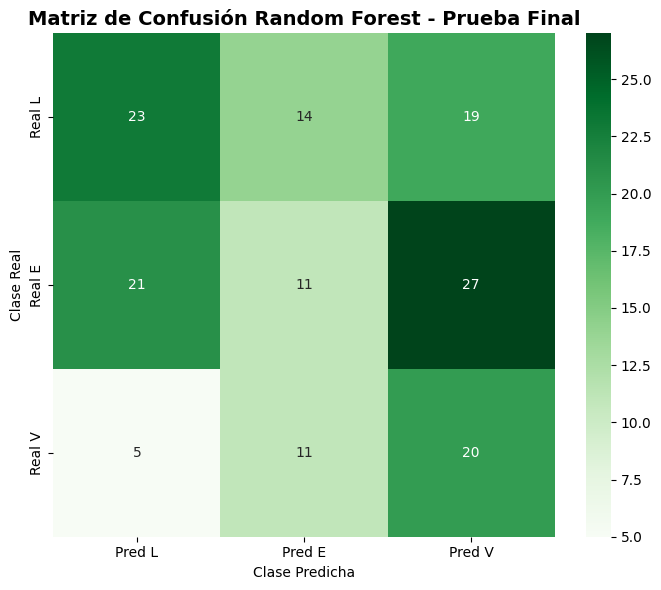

In [34]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_rf_test,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión Random Forest - Prueba Final",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "random_forest_prueba_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 29. Comparación de la distribución real frente a la predicha (Random Forest en prueba)
# Auditoría de la distribución de clases en la partición de prueba
Para examinar el comportamiento del modelo Random Forest optimizado sobre los datos de prueba no observados, comparo la distribución del conteo de clases reales frente a la frecuencia de las predicciones asignadas por el estimador.
En esta celda estructuro el DataFrame distribucion_rf_test calculando las frecuencias con .value_counts() sobre y_test y pred_rf_test. Utilizo .reindex(["L", "E", "V"], fill_value=0) para garantizar un orden uniforme de las tres categorías ("L", "E", "V") en la tabla resultante.

In [35]:
# estructurar la tabla comparativa de frecuencias reales vs. predichas para Random Forest
distribucion_rf_test = pd.DataFrame({
    "Real": (
        y_test
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    ),

    "Predicho": (
        pd.Series(
            pred_rf_test
        )
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    )
})

# desplegar la tabla de frecuencias en el conjunto de prueba
display(
    distribucion_rf_test
)

,Real,Predicho
L,56,49
E,59,36
V,36,66


# Celda 30 Validación vs. prueba
### 8.2. Estabilidad temporal del modelo
Comparo las métricas obtenidas durante la validación con las correspondientes al conjunto de prueba.
Esta comparación me permite observar cuánto cambia el comportamiento del Random Forest cuando se aplica a partidos cronológicamente posteriores y con una distribución diferente de resultados.

In [36]:
comparacion_rf_temporal = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro",
        "Log Loss"
    ],

    "Validación": [
        metricas_rf_validacion[
            "accuracy"
        ],
        metricas_rf_validacion[
            "precision_macro"
        ],
        metricas_rf_validacion[
            "recall_macro"
        ],
        metricas_rf_validacion[
            "f1_macro"
        ],
        metricas_rf_validacion[
            "log_loss"
        ]
    ],

    "Prueba": [
        metricas_rf_test[
            "accuracy"
        ],
        metricas_rf_test[
            "precision_macro"
        ],
        metricas_rf_test[
            "recall_macro"
        ],
        metricas_rf_test[
            "f1_macro"
        ],
        metricas_rf_test[
            "log_loss"
        ]
    ]
})

display(
    comparacion_rf_temporal.round(4)
)

,Métrica,Validación,Prueba
0,Accuracy,0.4029,0.3576
1,Precision Macro,0.3917,0.3593
2,Recall Macro,0.3990,0.3842
3,F1 Macro,0.3901,0.3539
4,Log Loss,1.0867,1.0862


# Celda 31 Comparación final con Regresión Logística

In [37]:
comparacion_modelos_test = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Logística",
        "Random Forest"
    ],

    "Accuracy": [
        baseline_test,
        0.3642,
        metricas_rf_test[
            "accuracy"
        ]
    ],

    "Precision Macro": [
        np.nan,
        0.3876,
        metricas_rf_test[
            "precision_macro"
        ]
    ],

    "Recall Macro": [
        np.nan,
        0.3824,
        metricas_rf_test[
            "recall_macro"
        ]
    ],

    "F1 Macro": [
        np.nan,
        0.3673,
        metricas_rf_test[
            "f1_macro"
        ]
    ],

    "Log Loss": [
        np.nan,
        1.0910,
        metricas_rf_test[
            "log_loss"
        ]
    ]
})

display(
    comparacion_modelos_test.round(4)
)

,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro,Log Loss
0,Baseline,0.3709,NaN,NaN,NaN,NaN
1,Regresión Logística,0.3642,0.3876,0.3824,0.3673,1.0910
2,Random Forest,0.3576,0.3593,0.3842,0.3539,1.0862


# Celda 32 Importancia de características
## 9. Importancia de las características
Analizo la importancia asignada por Random Forest a las características utilizadas durante la predicción.
Debido a que las variables categóricas fueron transformadas mediante One-Hot Encoding, recupero los nombres generados por el preprocesamiento antes de asociarlos con las importancias del modelo.

Este análisis tiene carácter interpretativo y no modifica la configuración seleccionada.

In [38]:
preprocesador_entrenado = (
    modelo_rf_final
    .named_steps[
        "preprocesamiento"
    ]
)

nombres_features = (
    preprocesador_entrenado
    .get_feature_names_out()
)

importancias = (
    modelo_rf_final
    .named_steps[
        "modelo"
    ]
    .feature_importances_
)

df_importancias = pd.DataFrame({
    "caracteristica":
        nombres_features,
    "importancia":
        importancias
})

df_importancias = (
    df_importancias
    .sort_values(
        "importancia",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    df_importancias.head(20)
)

,caracteristica,importancia
0,numericas__dif_ppg_historico,0.036224
1,numericas__dif_ppg_temporada,0.034252
2,numericas__visitante_gc_prom_historico_prev,0.032362
3,numericas__local_gf_prom_historico_prev,0.030329
4,numericas__dif_ppg_condicion,0.029719
5,numericas__visitante_ppg_condicion_prev,0.029094
6,numericas__visitante_gc_prom_condicion_prev,0.028744
7,numericas__local_ppg_historico_prev,0.028509
8,numericas__visitante_ppg_temporada_prev,0.028324
9,numericas__visitante_gc_prom_temporada_prev,0.028277


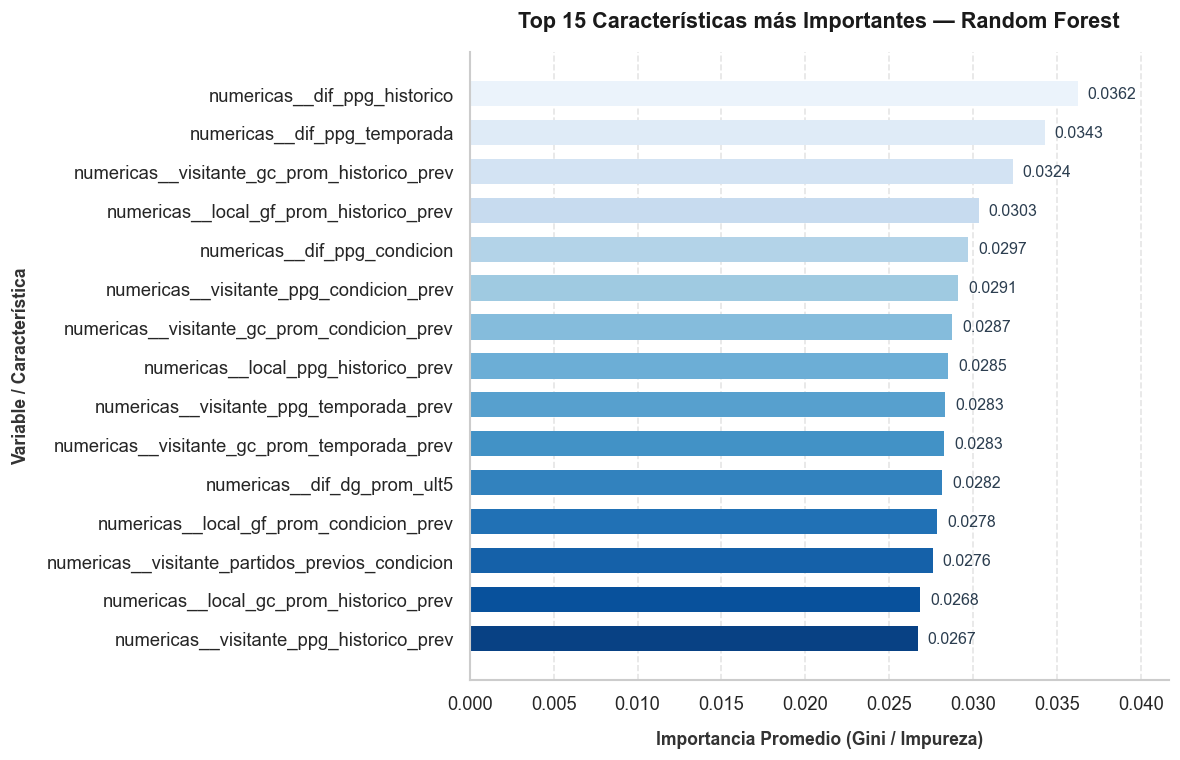

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

# configurar el estilo estético general
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(
    figsize=(10, 6.5),
    dpi=120
)

# generar el gráfico de barras horizontales con paleta degradada
bars = ax.barh(
    top_importancias["caracteristica"],
    top_importancias["importancia"],
    color=sns.color_palette("Blues_r", n_colors=len(top_importancias)),
    edgecolor="none",
    height=0.65
)

# agregar el valor numérico exacto al final de cada barra
for bar in bars:
    width = bar.get_width()
    ax.annotate(
        f"{width:.4f}",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9.5,
        fontweight="medium",
        color="#2c3e50"
    )

# personalizar títulos y etiquetas con tipografía limpia
ax.set_title(
    "Top 15 Características más Importantes — Random Forest",
    fontsize=13,
    fontweight="bold",
    pad=15,
    color="#1a1a1a"
)

ax.set_xlabel(
    "Importancia Promedio (Gini / Impureza)",
    fontsize=10.5,
    fontweight="semibold",
    labelpad=10,
    color="#333333"
)

ax.set_ylabel(
    "Variable / Característica",
    fontsize=10.5,
    fontweight="semibold",
    labelpad=10,
    color="#333333"
)

# ajustar el límite superior del eje X para que los números no queden cortados
max_val = top_importancias["importancia"].max()
ax.set_xlim(0, max_val * 1.15)

# simplificar la cuadrícula y remover bordes del marco
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.grid(axis="y", visible=False)

plt.tight_layout()

# guardar la figura en alta resolución
plt.savefig(
    FIGURES_DIR / "random_forest_importancia_caracteristicas.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Celda 33 Guardar modelo

In [42]:
import joblib

RUTA_MODELO_RF = (
    MODELS_DIR
    / "random_forest_lpf.joblib"
)

joblib.dump(
    modelo_rf_final,
    RUTA_MODELO_RF
)

print(
    "Modelo guardado en:"
)

print(
    RUTA_MODELO_RF
)

print(
    "Existe:",
    RUTA_MODELO_RF.exists()
)

Modelo guardado en:
C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\models\random_forest_lpf.joblib
Existe: True


## 11. Conclusión del modelo Random Forest
Después de completar la búsqueda de hiperparámetros, seleccioné un Random Forest compuesto por 500 árboles, una profundidad máxima de 6 niveles, un mínimo de 5 observaciones por hoja y ponderación balanceada de las clases.
Durante la etapa de validación, esta configuración alcanzó un Accuracy de 40.29 %, un F1-Score Macro de 39.01 % y un Log Loss de 1.0867, superando ligeramente a la Regresión Logística en este periodo.
Volví a entrenar el modelo utilizando los 2,075 partidos correspondientes a entrenamiento y validación y realicé una única evaluación sobre los 151 encuentros reservados como prueba.

En este conjunto obtuve un Accuracy de 35.76 %, Precision Macro de 35.93 %, Recall Macro de 38.42 %, F1-Score Macro de 35.39 % y Log Loss de 1.0862. La exactitud fue inferior al baseline de clase mayoritaria, establecido en 37.09 %, y también menor a la obtenida por la Regresión Logística.
La principal dificultad continuó siendo la clasificación de los empates, con un F1-Score de 23.16 %. También observé una tendencia a sobreestimar las victorias visitantes, ya que el modelo generó 66 predicciones de esta categoría frente a 36 casos reales.
El análisis de importancia de características mostró que las diferencias de puntos por partido histórico, de temporada y según condición de localía se encontraban entre las variables más utilizadas por el bosque. También destacaron los promedios históricos de goles anotados y recibidos, lo que respalda la utilidad de las características de rendimiento construidas previamente.
Los resultados muestran que la capacidad de Random Forest para representar relaciones no lineales produjo una mejora moderada durante validación, pero esta ventaja no se mantuvo sobre los partidos más recientes. Conservo el modelo como parte de la comparación del sistema y utilizaré sus resultados posteriormente para contrastarlos con XGBoost y con el modelo estadístico basado en Poisson.